#Exploratory Data Analysis

This dataset is composed by 5000 CVs...

In [1]:
!pip3 install pandas
!pip install adjustText

In [33]:
import json
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from adjustText import adjust_text
import networkx as nx

In [ ]:

import json
import pandas as pd

def readfiles(raw_data_path):
    raw_path = Path(raw_data_path)
    texts = []
    annotations_ = []

    for json_file in raw_path.rglob("*.json"):
        with open(json_file, 'r', encoding='utf-8', errors='replace') as f:
            data = json.load(f)
            
            text = data.get("text", "")
            
            # Clean lone surrogates that crash PyArrow/Pandas
            if isinstance(text, str):
                text = text.encode("utf-8", "surrogatepass").decode("utf-8", "ignore")
            
            annotations = data.get("annotations", [])

            texts.append(text)
            annotations_.append(annotations)
            
    df_skills = pd.DataFrame({"text": texts, "annotations": annotations_})
    return df_skills

In [4]:
df_skills = readfiles("data/raw")

In [5]:
df_skills.head()

,text,annotations
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI..."


In [6]:
df_skills["annotations"][0:2].tolist()

[[[657, 665, 'SKILL: Building'],
  [822, 828, 'SKILL: python'],
  [811, 815, 'SKILL: java'],
  [781, 790, 'SKILL: Knowledge'],
  [877, 887, 'SKILL: Processing'],
  [194, 205, 'SKILL: performance'],
  [442, 452, 'SKILL: Technology'],
  [1007, 1014, 'SKILL: PySpark'],
  [30, 44, 'SKILL: Data Scientist'],
  [153, 162, 'SKILL: Detection'],
  [329, 345, 'SKILL: computer science'],
  [102, 108, 'SKILL: Images'],
  [889, 902, 'SKILL: Deep Learning'],
  [942, 954, 'SKILL: data science'],
  [1031, 1037, 'SKILL: skills'],
  [1147, 1155, 'SKILL: Projects'],
  [734, 737, 'SKILL: CAN'],
  [575, 590, 'SKILL: Market Research'],
  [956, 969, 'SKILL: Data Analysis'],
  [904, 919, 'SKILL: Computer Vision'],
  [802, 809, 'SKILL: Process'],
  [817, 818, 'SKILL: C'],
  [164, 167, 'SKILL: OCR'],
  [604, 612, 'SKILL: Analysis'],
  [838, 846, 'SKILL: Learning'],
  [971, 988, 'SKILL: Software Engineer'],
  [338, 345, 'SKILL: Science'],
  [267, 278, 'SKILL: Probability'],
  [772, 780, 'SKILL: Exchange'],
  [379

In [7]:
def extract_skills(annotation_list):
    # This list comprehension pulls the string from index 2 of each sub-list
    return [item[2] for item in annotation_list]

# Create the new column
df_skills['skills_list'] = df_skills['annotations'].apply(extract_skills)

# Optional: If you want a single string separated by commas instead of a list:
# df_skills['skills_string'] = df_skills['skills_list'].apply(lambda x: ", ".join(x))

In [8]:
df_skills.head()


,text,annotations,skills_list
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[SKILL: Building, SKILL: python, SKILL: java, ..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[SKILL: scikit, SKILL: python, SKILL: Scikit l..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[SKILL: WINDOWS XP, SKILL: Problem solving, SK..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,..."


In [9]:
df_skills["skills_list"][0]

['SKILL: Building',
 'SKILL: python',
 'SKILL: java',
 'SKILL: Knowledge',
 'SKILL: Processing',
 'SKILL: performance',
 'SKILL: Technology',
 'SKILL: PySpark',
 'SKILL: Data Scientist',
 'SKILL: Detection',
 'SKILL: computer science',
 'SKILL: Images',
 'SKILL: Deep Learning',
 'SKILL: data science',
 'SKILL: skills',
 'SKILL: Projects',
 'SKILL: CAN',
 'SKILL: Market Research',
 'SKILL: Data Analysis',
 'SKILL: Computer Vision',
 'SKILL: Process',
 'SKILL: C',
 'SKILL: OCR',
 'SKILL: Analysis',
 'SKILL: Learning',
 'SKILL: Software Engineer',
 'SKILL: Science',
 'SKILL: Probability',
 'SKILL: Exchange',
 'SKILL: M',
 'SKILL: vision',
 'SKILL: Communications',
 'SKILL: Language Processing',
 'SKILL: Team',
 'SKILL: Data',
 'SKILL: Natural Language Processing',
 'SKILL: Engineer',
 'SKILL: Object detection',
 'SKILL: Pattern',
 'SKILL: Computer Science Engineering',
 'SKILL: machine learning',
 'SKILL: Kubeflow',
 'SKILL: Research',
 'SKILL: Patterns',
 'SKILL: Premium',
 'SKILL: Probl

In [10]:
df_skills["num_annon"]=df_skills["skills_list"].apply(len)

<Axes: >

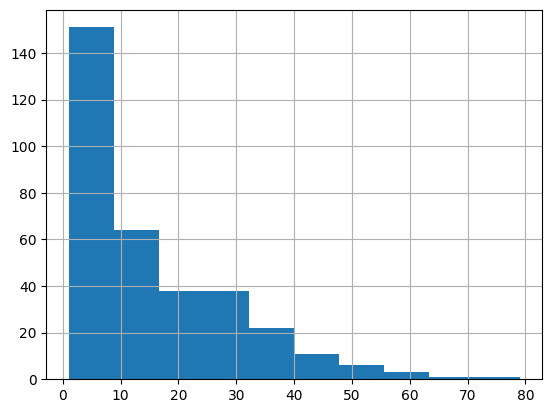

In [11]:
df_skills["num_annon"].value_counts().hist()

#Há uma tendência para os currículso terem, em média, 10 annotações.

#Verificar se são todas skills ou não

In [12]:
df_skills["skills_list"]

0       [SKILL: Building, SKILL: python, SKILL: java, ...
1       [SKILL: scikit, SKILL: python, SKILL: Scikit l...
2       [SKILL: reporting, SKILL: Business Studies, SK...
3       [SKILL: WINDOWS XP, SKILL: Problem solving, SK...
4       [SKILL: Test cases, SKILL: GMail, SKILL: java,...
                              ...                        
5024    [SKILL: Sensor, SKILL: Music, SKILL: Advertisi...
5025    [SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...
5026    [SKILL: Reports, SKILL: VMware, SKILL: Typing,...
5027    [SKILL: Inventory, SKILL: GMail, SKILL: Knowle...
5028    [SKILL: Debugging skills, SKILL: Ability, SKIL...
Name: skills_list, Length: 5029, dtype: object

In [13]:
["abc", "def", "ghi"] + ["jkl", "mno"]

['abc', 'def', 'ghi', 'jkl', 'mno']

In [14]:
unique_skills = df_skills["skills_list"].explode().unique().tolist()

In [15]:
len(unique_skills)

12696

In [16]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skills_list
SKILL: COM                       3874
SKILL: skills                    3805
SKILL: Work                      3679
SKILL: Personal                  3458
SKILL: Knowledge                 3417
                                 ... 
SKILL: Information Governance       1
SKILL: Clinical teams               1
SKILL: Big Bang                     1
SKILL: iHeart Radio                 1
SKILL: Debugging skills             1
Name: count, Length: 12695, dtype: int64


<Axes: xlabel='skills_list'>

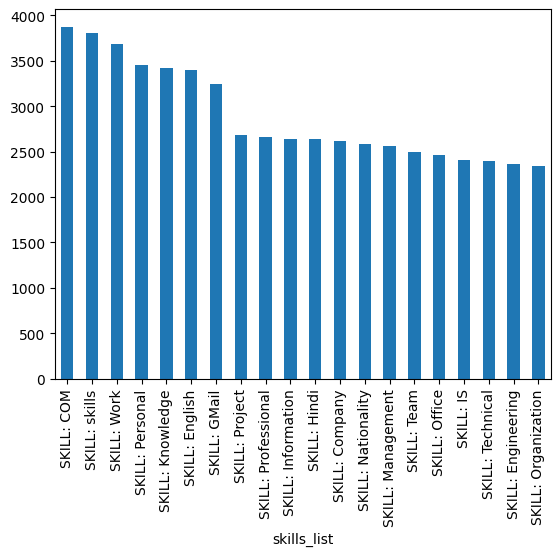

In [17]:
skill_counts.head(20).plot(kind='bar')

In [18]:
df_skills

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[SKILL: Building, SKILL: python, SKILL: java, ...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[SKILL: scikit, SKILL: python, SKILL: Scikit l...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[SKILL: WINDOWS XP, SKILL: Problem solving, SK...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
...,...,...,...,...
5024,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
5025,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
5026,RESUME\nName :Gaurav Dwivedi\nAge :27 Years\nD...,"[[2070, 2077, SKILL: Reports], [2399, 2405, SK...","[SKILL: Reports, SKILL: VMware, SKILL: Typing,...",72
5027,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [19]:
df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]

,text,annotations,skills_list,num_annon
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
6,"\t\n\t\n\t\n\t\n\t\n\t\nBarbara Farman, Hair,...","[[787, 793, SKILL: Hunter], [1618, 1624, SKILL...","[SKILL: Hunter, SKILL: Health, SKILL: ADAMS, S...",36
7,"\n2632 La Cienega Avenue Los Angeles, C...","[[847, 853, SKILL: Hunter], [2447, 2451, SKILL...","[SKILL: Hunter, SKILL: COLA, SKILL: Australia,...",23
8,"\n \n \n \nBethany Newell, Manicurist \nwww.c...","[[968, 980, SKILL: Self service], [1799, 1805,...","[SKILL: Self service, SKILL: Forbes, SKILL: co...",21
...,...,...,...,...
5023,"\n \n \n \nDenika Bedrossian , Makeup Artist...","[[105, 109, SKILL: ADAM], [3504, 3512, SKILL: ...","[SKILL: ADAM, SKILL: Big Bang, SKILL: CAN, SKI...",38
5024,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
5025,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
5027,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [20]:
x=df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]
[ano for ano in x["annotations"].iloc[0] if "SKILL: COM" in ano]


[[103, 106, 'SKILL: COM']]

In [21]:
df_skills["text"][2][95:120]

'y@yahoo.com\nSummary\nProfi'

In [22]:
#Remover Prefixo "Skill"

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda x: [item.split(': ')[-1] if ': ' in item else item for item in x]
)

In [23]:
df_skills.head()

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[Building, python, java, Knowledge, Processing...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[scikit, python, Scikit learn, TensorFlow, Dee...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[reporting, Business Studies, Managing, Maths,...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[WINDOWS XP, Problem solving, Knowledge, Arts,...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[Test cases, GMail, java, Knowledge, ASP, Crit...",80


In [24]:
df_skills["skills_list"].explode().value_counts()

skills_list
COM                             3874
skills                          3805
Work                            3679
Personal                        3458
Knowledge                       3417
                                ... 
Research Programs                  1
Continuing Medical Education       1
Big Bang                           1
iHeart Radio                       1
Debugging skills                   1
Name: count, Length: 12693, dtype: int64

In [25]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

def clean_skills_text(skills_list):
    stop_words = set(stopwords.words('english'))
    cleaned_list = []
    for skill in skills_list:

        words = skill.split()
        filtered_words = [w for w in words if w.lower() not in stop_words]
        cleaned_skill = " ".join(filtered_words).strip()
        if cleaned_skill:
            cleaned_list.append(cleaned_skill)
            
    return cleaned_list

df_skills['skills_list'] = df_skills['skills_list'].apply(clean_skills_text)

df_skills['skills_list'] = df_skills['skills_list'].apply(lambda x: list(set(x)))

In [26]:
#Remover skills genéricas e não relevantes
blacklist = {"COM", "Skills" , "personal","information", "knowledge", "process", "skills", "can", "work", "marital status", "nationality", "com", "languages", "board", "email", "qualification","activities"}

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [s for s in lista if s.lower() not in blacklist]
)


In [27]:
#Colocar em minusculas

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: list(set([s.lower().strip() for s in lista]))
)

print(df_skills['skills_list'].head())

df_skills["skills_list"].explode().count()

0    [research, commerce, application building, dat...
1    [r, anaconda, parking, tech, masters, streamli...
2    [communication, standards, commerce, salary, m...
3    [manager, gender, internet, academic, ph, ltd,...
4    [asp, stlc, critical thinking, computer scienc...
Name: skills_list, dtype: object


np.int64(493902)

skills_list
english               3399
gmail                 3238
project               2683
professional          2661
hindi                 2636
                      ... 
medical management       1
clinical problems        1
big bang                 1
iheart radio             1
debugging skills         1
Name: count, Length: 12569, dtype: int64


<Axes: xlabel='skills_list'>

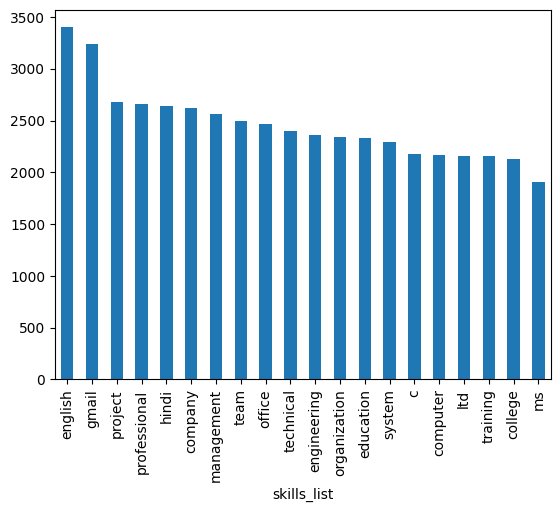

In [28]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skill_counts.head(20).plot(kind='bar')

#Removemos conectores(e.g "is") e outras skills que não eram relevantes"

Será que existem skills relacionadas?

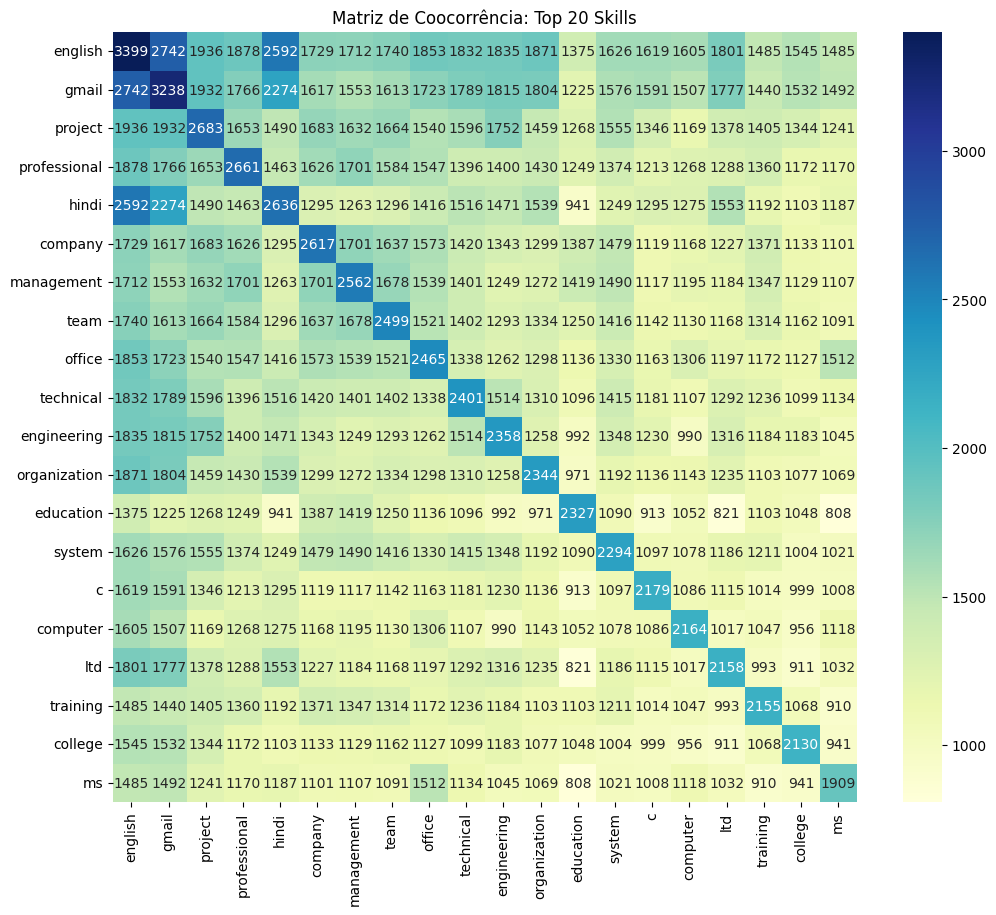

In [29]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
skills_encoded = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), 
                             columns=mlb.classes_, 
                             index=df_skills.index)

top_20_skills = df_skills['skills_list'].explode().value_counts().head(20).index
subset_encoded = skills_encoded[top_20_skills]

co_occurrence_matrix = subset_encoded.T.dot(subset_encoded)

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence_matrix, annot=True, fmt="d", cmap="YlGnBu")
plt.title('Matriz de Coocorrência: Top 20 Skills')
plt.show()

E quais são as mais raras?

In [30]:
total_cvs = len(df_skills)
skill_counts = df_skills['skills_list'].explode().value_counts()

skills_stats = pd.DataFrame({
    'contagem': skill_counts,
    'percentagem': (skill_counts / total_cvs) * 100
})

limite_raridade = 1.0 
skills_raras = skills_stats[skills_stats['percentagem'] < limite_raridade]

print(f"Total de skills únicas: {len(skill_counts)}")
print(f"Total de skills raras (<{limite_raridade}%): {len(skills_raras)}")
print("\nExemplos de Skills Raras:")
print(skills_raras.tail(30))

Total de skills únicas: 12569
Total de skills raras (<1.0%): 11084

Exemplos de Skills Raras:
                              contagem  percentagem
skills_list                                        
capital iq                           1     0.019885
cash flow modeling                   1     0.019885
quantitative modeling                1     0.019885
correspondence preparation           1     0.019885
law degree                           1     0.019885
legal assistance                     1     0.019885
client focus                         1     0.019885
oid                                  1     0.019885
bain                                 1     0.019885
independent decision making          1     0.019885
advanced research                    1     0.019885
language fluency                     1     0.019885
medical imaging                      1     0.019885
pharmacovigilance                    1     0.019885
continuing medical education         1     0.019885
clinical teams        

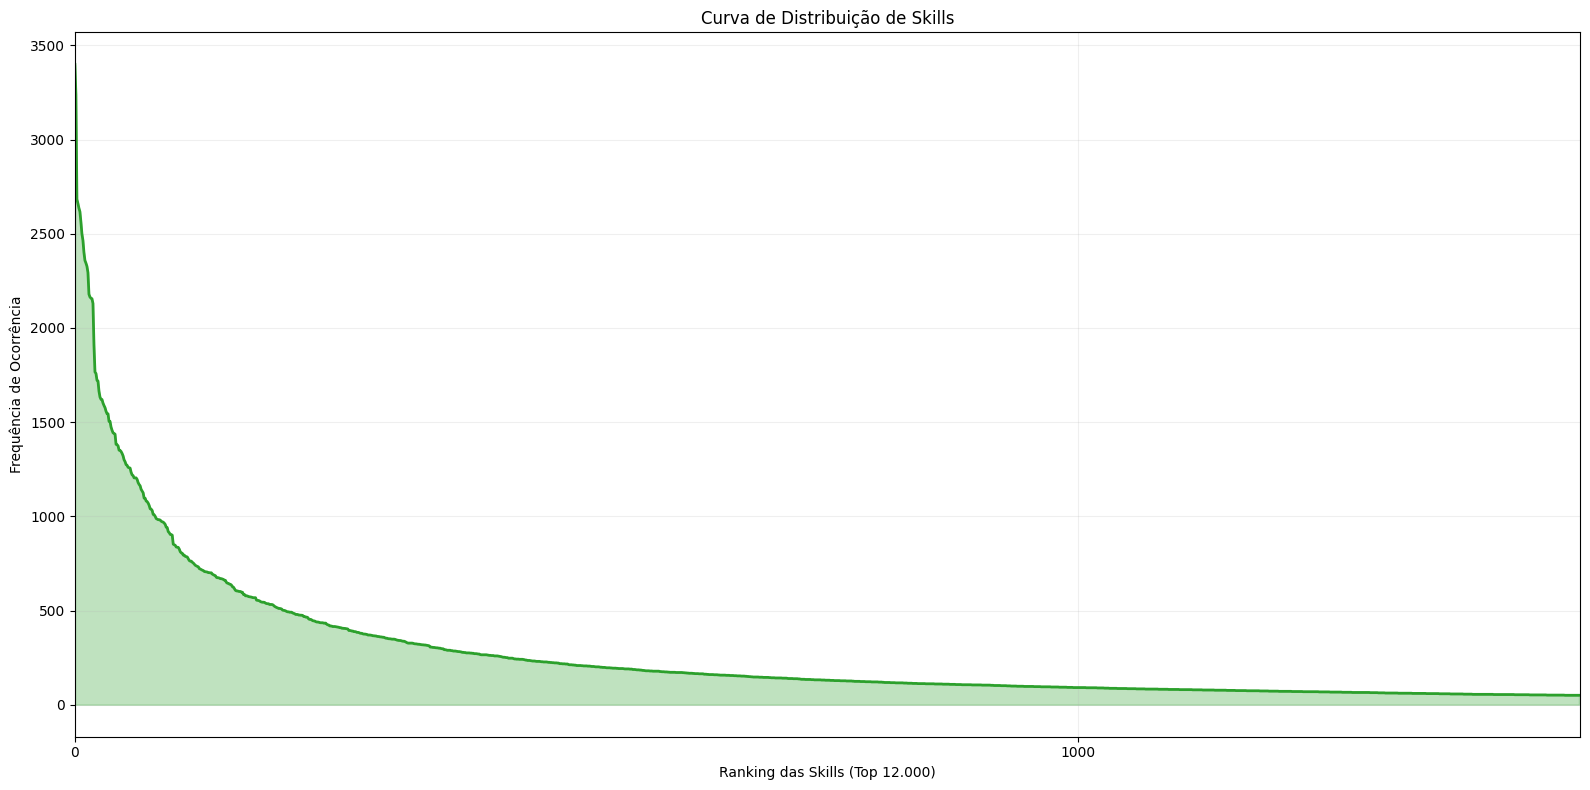

In [39]:
#Gráfico com frequência das skills

counts = df_skills['skills_list'].explode().value_counts()

top_n = 1500
counts_subset = counts.head(top_n)
x_values = np.arange(len(counts_subset))

plt.figure(figsize=(16, 8))

plt.plot(range(len(counts_subset)), counts_subset.values, color='#2ca02c', linewidth=2)
plt.fill_between(range(len(counts_subset)), counts_subset.values, color='#2ca02c', alpha=0.3)

#plt.yscale() 

plt.xlabel('Ranking das Skills (Top 12.000)')
plt.ylabel('Frequência de Ocorrência')
plt.title('Curva de Distribuição de Skills')

plt.xticks(np.arange(0, top_n + 1, 1000))
plt.grid(True, which="both", ls="-", alpha=0.2)

plt.xlim(0, top_n)
plt.tight_layout()
plt.show()

In [64]:
#Remover as mais raras (<5%)
skill_counts = df_skills['skills_list'].explode().value_counts()
rare_skills = skill_counts[skill_counts < (len(df_skills) * 0.05)].index
df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [s for s in lista if s not in rare_skills]
)
df_skills['skills_list'].explode().value_counts().count()

np.int64(429)

Usar mais comuns ou raras?

Vamos agrupar por skills que aparecem nos mesmo CVs e depois por tipos de cvs

Grupos de skills que aparecem nos mesmo CVs

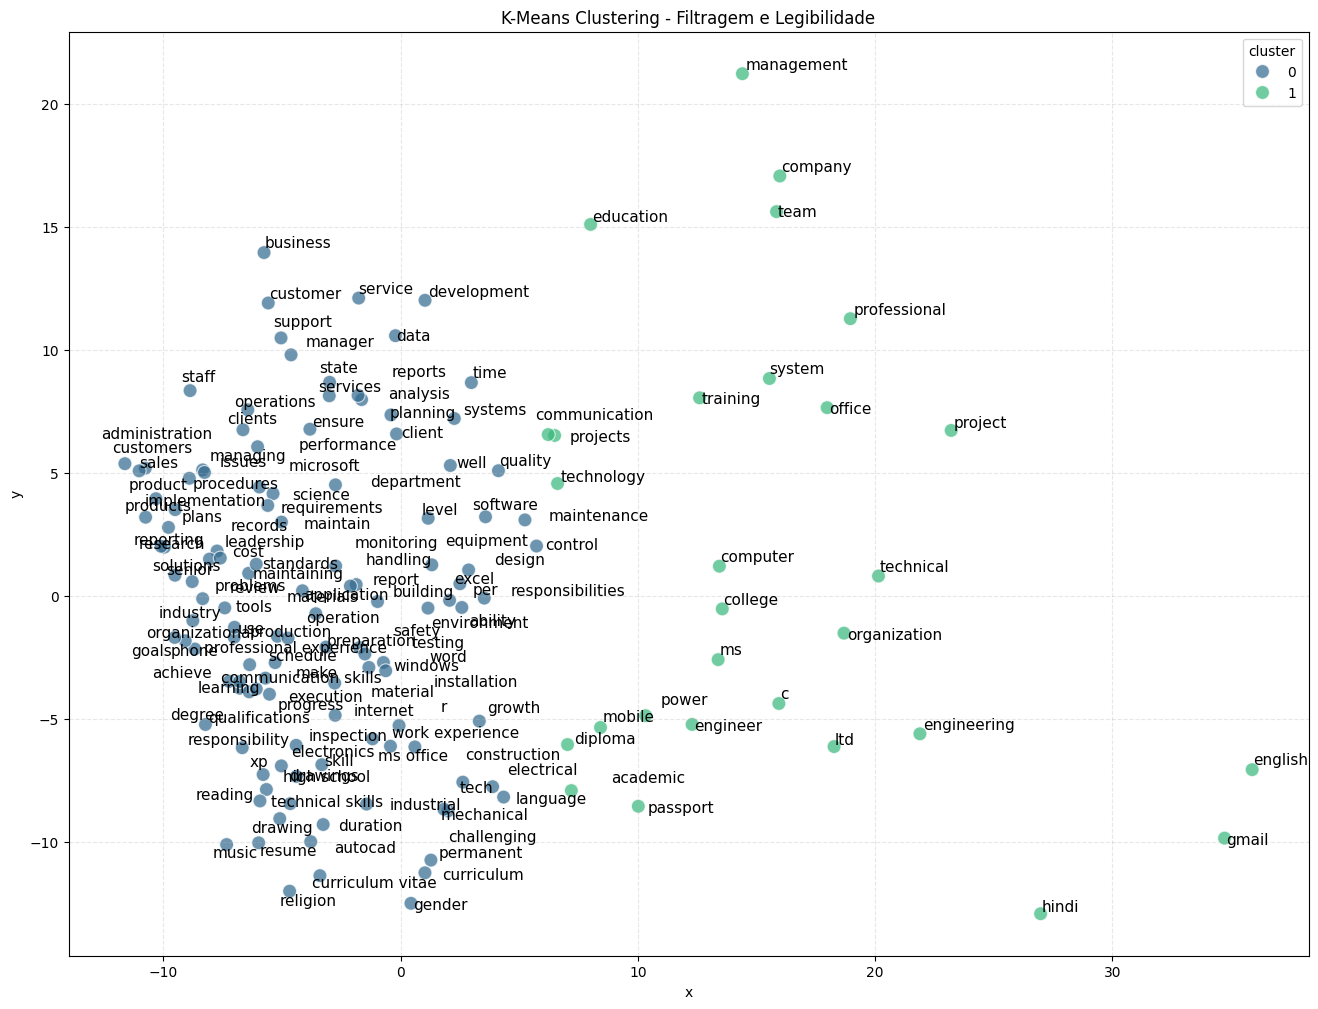

In [66]:
#Professor: Limite a 150 skills porque se não é ilegível. Fiz com vários grupos mas visualmente só acho relevante 2/3

mlb = MultiLabelBinarizer()
skills_matrix = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), columns=mlb.classes_)

min_occurrence = 50 
frequent_skills = skills_matrix.columns[skills_matrix.sum() > min_occurrence]

if len(frequent_skills) > 150:
    frequent_skills = skills_matrix.sum().sort_values(ascending=False).head(150).index

matrix_to_cluster = skills_matrix[frequent_skills].T

n_clusters = 2
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters = kmeans.fit_predict(matrix_to_cluster)

pca = PCA(n_components=2)
reduced_data = pca.fit_transform(matrix_to_cluster)

plt.figure(figsize=(16, 12))
scatter_df = pd.DataFrame({
    'x': reduced_data[:, 0],
    'y': reduced_data[:, 1],
    'label': frequent_skills,
    'cluster': clusters
})

sns.scatterplot(data=scatter_df, x='x', y='y', hue='cluster', palette='viridis', s=100, alpha=0.7)

texts = []
for i in range(len(scatter_df)):
    texts.append(plt.text(scatter_df.x[i], scatter_df.y[i], scatter_df.label[i], fontsize=11))

adjust_text(texts, force_points=0.2, force_text=0.2, expand_points=(1.2, 1.2))

plt.title('K-Means Clustering - Filtragem e Legibilidade')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

Tipos de perfis de acordo com as palavras principais/iniciais

Perfil 0: management, systems, data, support, system, microsoft, technology, software, network, science
Perfil 1: management, business, customer, development, skills, team, communication, service, office, financial
Perfil 2: data, learning, analysis, science, software, development, sql, analytics, machine, language
Perfil 3: project, electrical, engineering, management, maintenance, technical, engineer, quality, safety, control
Perfil 4: skills, english, gmail, computer, ms, communication, office, hindi, technical, engineering


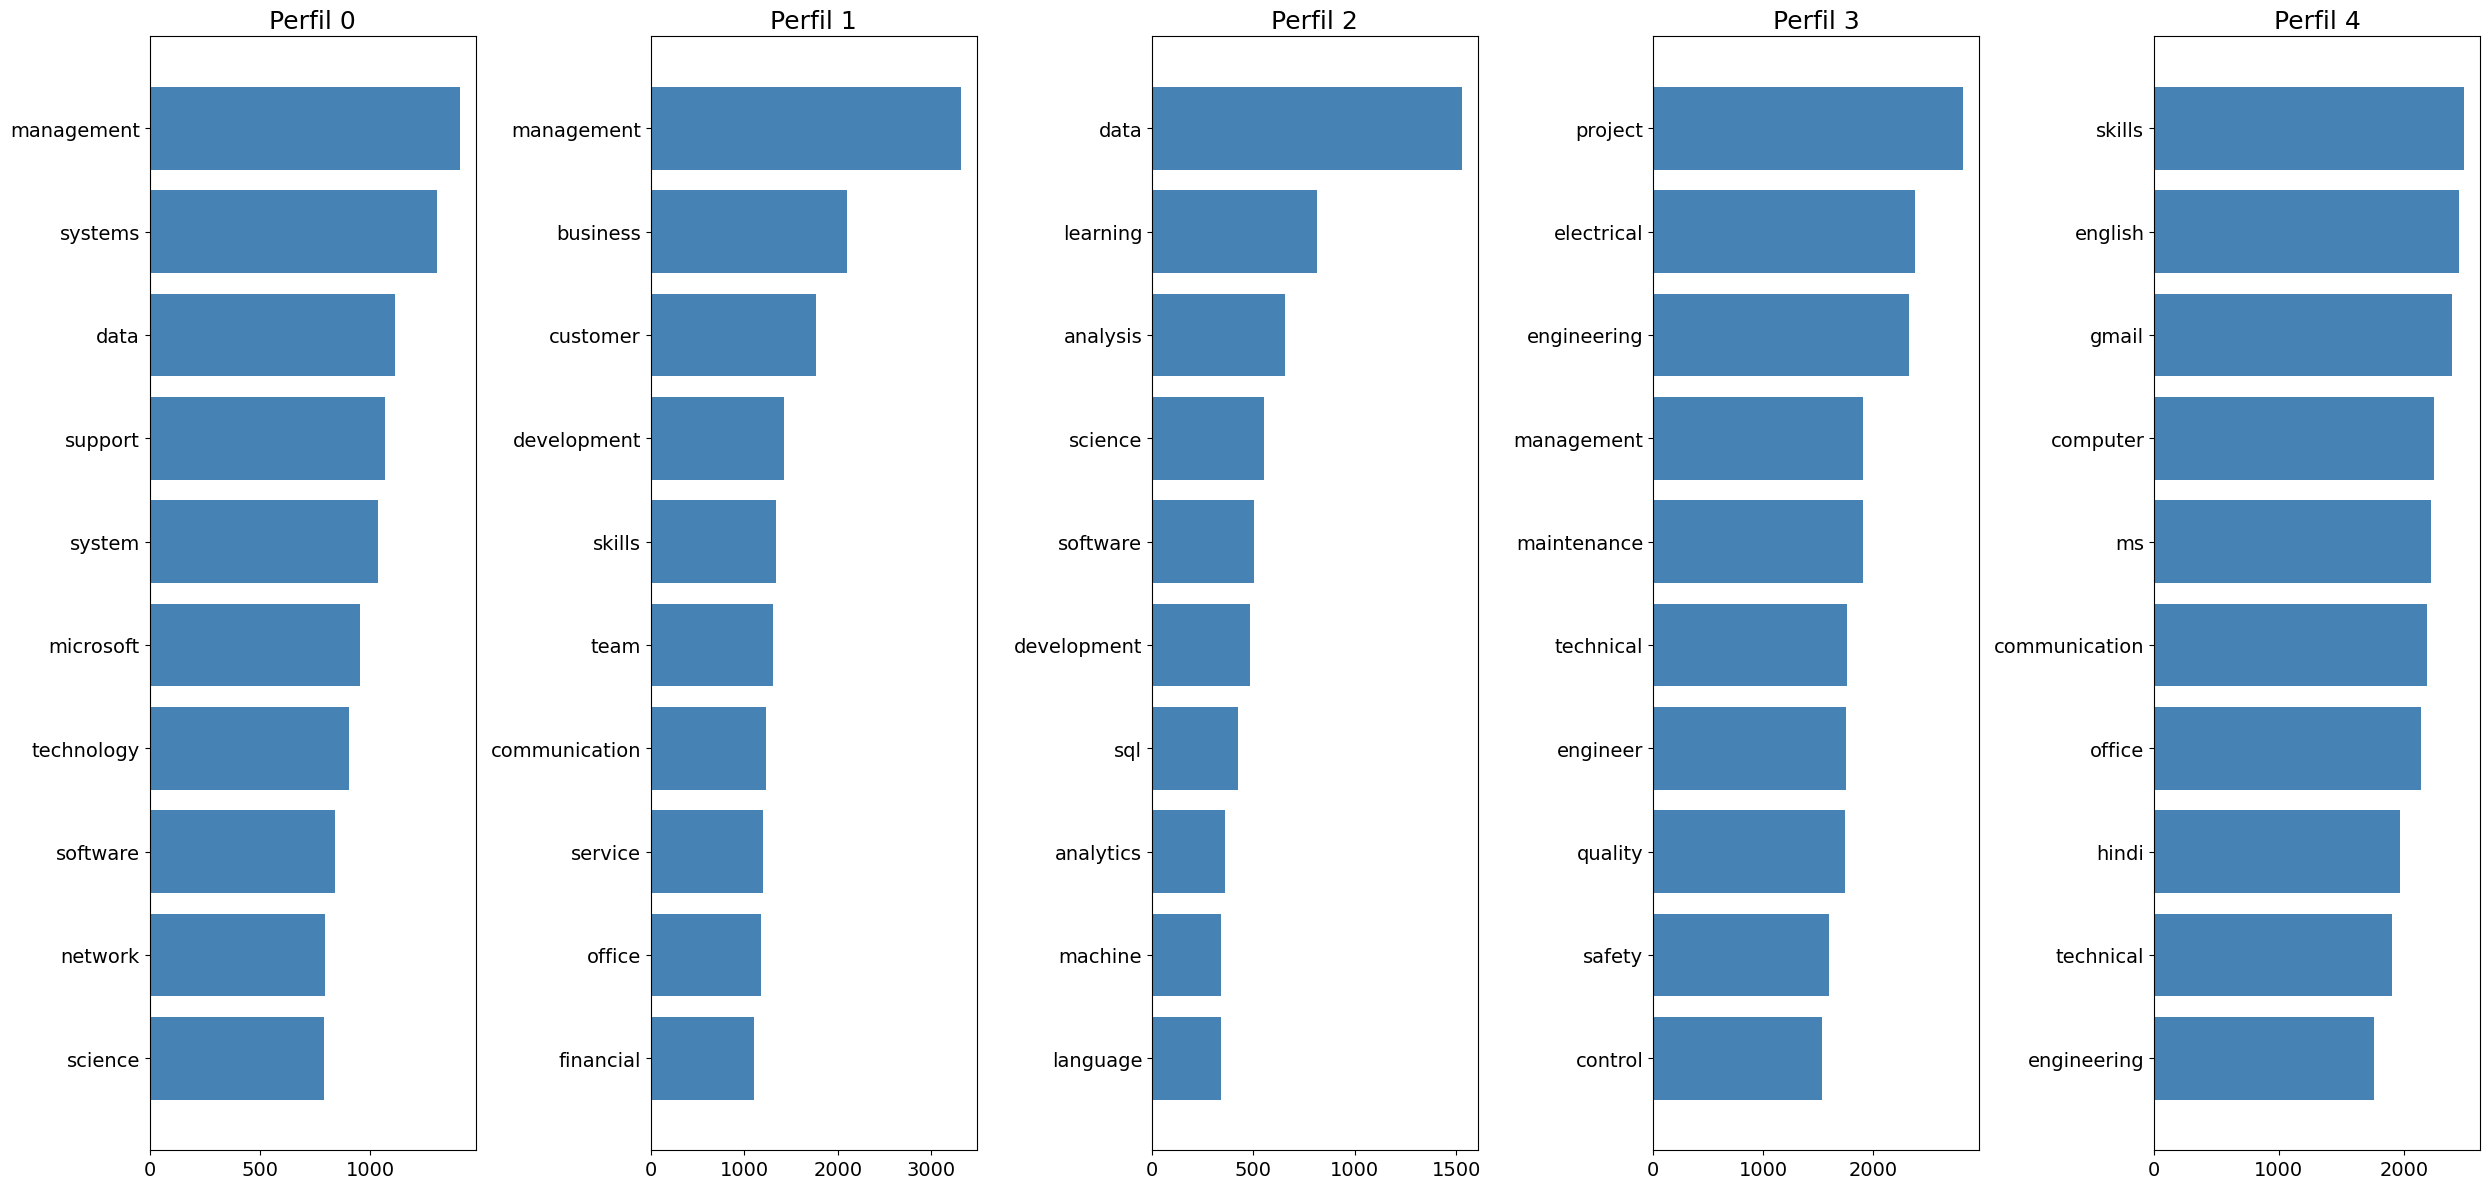

In [40]:
skills_as_sentences = df_skills['skills_list'].apply(lambda x: " ".join(x))
vectorizer = CountVectorizer()
doc_term_matrix = vectorizer.fit_transform(skills_as_sentences)

n_topics = 5
lda = LatentDirichletAllocation(n_components=n_topics, random_state=42)
lda.fit(doc_term_matrix)

words = vectorizer.get_feature_names_out()
fig, axes = plt.subplots(1, n_topics, figsize=(25, 12), sharex=False)
axes = axes.flatten()

for topic_idx, topic in enumerate(lda.components_):
    top_features_ind = topic.argsort()[:-11:-1]
    top_features = [words[i] for i in top_features_ind]
    weights = topic[top_features_ind]

    ax = axes[topic_idx]
    ax.barh(top_features, weights, color='steelblue')
    ax.set_title(f'Perfil {topic_idx}', fontdict={'fontsize': 18})
    ax.invert_yaxis()
    ax.tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
plt.savefig('lda_viz.png')

for topic_idx, topic in enumerate(lda.components_):
    top_words = [words[i] for i in topic.argsort()[:-11:-1]]
    print(f"Perfil {topic_idx}: {', '.join(top_words)}")

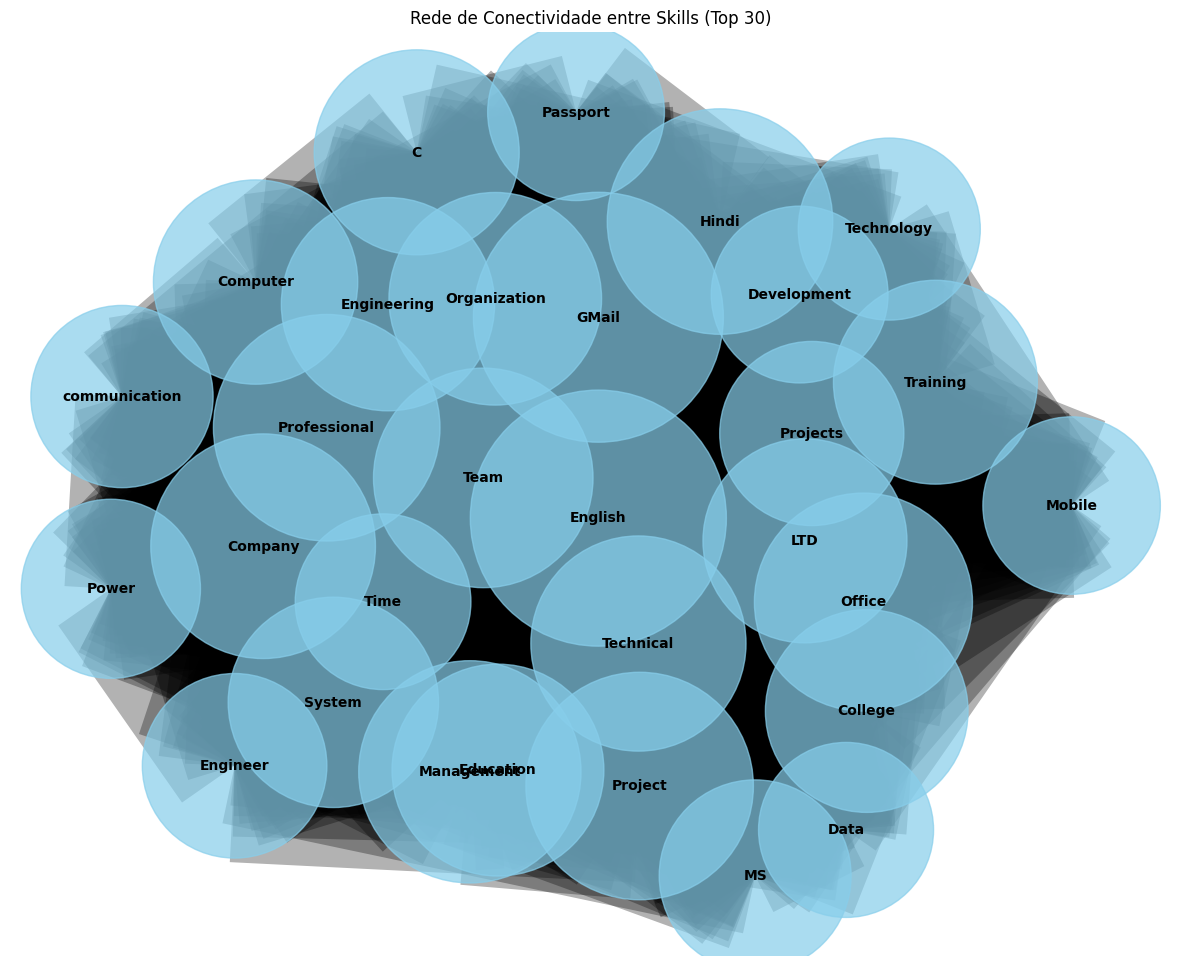

In [53]:

def generate_network_graph(df, min_edge_weight=5, top_n=30):
    mlb = MultiLabelBinarizer()
    skills_encoded = pd.DataFrame(mlb.fit_transform(df['skills_list']), columns=mlb.classes_)
    
    top_skills = df['skills_list'].explode().value_counts().head(top_n).index
    subset_encoded = skills_encoded[top_skills]
    
    co_occurrence = subset_encoded.T.dot(subset_encoded)
    
    G = nx.Graph()
    
    for i in range(len(co_occurrence.columns)):
        for j in range(i + 1, len(co_occurrence.columns)):
            weight = co_occurrence.iloc[i, j]
            if weight > min_edge_weight:
                G.add_edge(co_occurrence.columns[i], co_occurrence.columns[j], weight=weight)
    
    plt.figure(figsize=(15, 12))
    pos = nx.spring_layout(G, k=0.5, seed=42)
    
    counts = df['skills_list'].explode().value_counts()
    node_size = [counts[node] * 10 for node in G.nodes()]
    
    nx.draw_networkx_nodes(G, pos, node_size=node_size, node_color='skyblue', alpha=0.7)
    nx.draw_networkx_edges(G, pos, width=[G[u][v]['weight']/10 for u,v in G.edges()], alpha=0.3)
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    
    plt.title('Rede de Conectividade entre Skills (Top 30)')
    plt.axis('off')
    plt.show()

generate_network_graph(df_skills)

C:\Users\duart\AppData\Local\Temp\ipykernel_13632\569013178.py:34: UserWarning: 

The connectionstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(


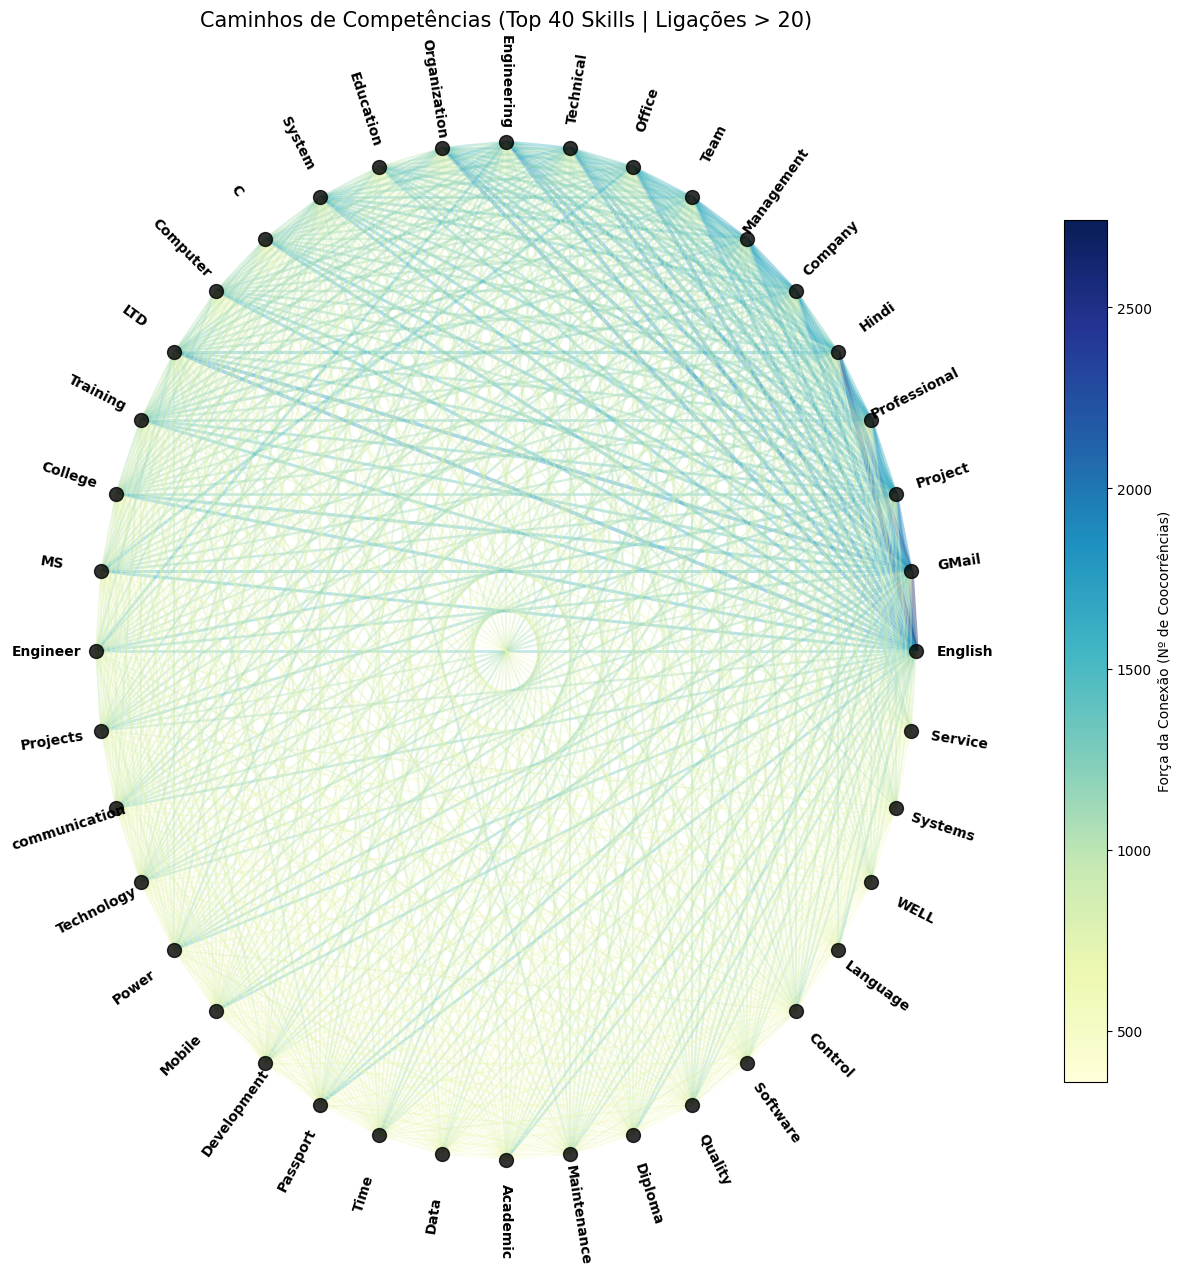

In [58]:

def generate_circular_network(df, min_edge_weight=15, top_n=40):
    mlb = MultiLabelBinarizer()
    encoded = pd.DataFrame(mlb.fit_transform(df['skills_list']), columns=mlb.classes_)
    
    top_skills = df['skills_list'].explode().value_counts().head(top_n).index
    subset = encoded[top_skills]
    co_occurrence = subset.T.dot(subset)

    G = nx.Graph()

    for i in range(len(co_occurrence.columns)):
        for j in range(i + 1, len(co_occurrence.columns)):
            weight = co_occurrence.iloc[i, j]
            if weight > min_edge_weight:
                G.add_edge(co_occurrence.columns[i], co_occurrence.columns[j], weight=weight)

    plt.figure(figsize=(16, 16))
    
    pos = nx.circular_layout(G)
    
    edges = G.edges(data=True)
    weights = [d['weight'] for u, v, d in edges]
    
    if weights:
        max_w = max(weights)
        edge_widths = [(w / max_w) * 4 for w in weights]
        edge_colors = weights
    else:
        edge_widths = 1
        edge_colors = 'gray'

    nx.draw_networkx_nodes(G, pos, node_size=100, node_color='black', alpha=0.8)
    
    nx.draw_networkx_edges(
        G, pos, 
        width=edge_widths, 
        edge_color=edge_colors, 
        edge_cmap=plt.cm.YlGnBu, 
        alpha=0.4,
        connectionstyle="arc3,rad=0.1"
    )

    label_pos = {k: v * 1.12 for k, v in pos.items()}
    
    for node, (x, y) in label_pos.items():
        angle = np.arctan2(y, x) * 180 / np.pi
        plt.text(x, y, node, 
                 fontsize=10, 
                 fontweight='bold', 
                 ha='center', 
                 va='center', 
                 rotation=angle if -90 < angle < 90 else angle + 180)

    sm = plt.cm.ScalarMappable(cmap=plt.cm.YlGnBu, norm=plt.Normalize(vmin=min(weights) if weights else 0, vmax=max(weights) if weights else 1))
    plt.colorbar(sm, ax=plt.gca(), label='Força da Conexão (Nº de Coocorrências)', shrink=0.7)

    plt.title(f'Caminhos de Competências (Top {top_n} Skills | Ligações > {min_edge_weight})', fontsize=15)
    plt.axis('off')
    plt.show()

import numpy as np
generate_circular_network(df_skills, min_edge_weight=20, top_n=40)